In [13]:

from pathlib import Path
import sys
import numpy as np

# Mencari folder utama BAJANG TACTIC
current_path = Path.cwd().resolve()

project_path = None

for path in [current_path, *current_path.parents]:
    if (path / "official-repository").exists() and (path / "src").exists():
        project_path = path
        break

if project_path is None:
    raise FileNotFoundError(
        "Folder utama BAJANG TACTIC tidak ditemukan."
    )

# Menambahkan folder proyek agar modul src bisa diimpor
sys.path.insert(0, str(project_path))

# Lokasi dataset
data_path = (
    project_path
    / "official-repository"
    / "more-than-a-hack-2027"
    / "data"
    / "tactical"
)

atd_path = data_path / "BAR-ATH_tactical_atd.txt"
metadata_path = data_path / "BAR-ATH_tactical_atd.xml"

print("Project ditemukan:", project_path)
print("Dataset ditemukan:", data_path)
print("ATD tersedia:", atd_path.exists())
print("Metadata tersedia:", metadata_path.exists())


Project ditemukan: D:\BAJANG TACTIC
Dataset ditemukan: D:\BAJANG TACTIC\official-repository\more-than-a-hack-2027\data\tactical
ATD tersedia: True
Metadata tersedia: True


In [14]:

from src.data_loader import load_metadata

# Membaca metadata tim dan pemain
metadata = load_metadata(metadata_path)

# Menampilkan informasi tim
print("Home team:", metadata["home_name"])
print("Away team:", metadata["away_name"])

# Mengambil mapping track slot
team_mapping = metadata["team_mapping"]

print("\nJumlah track slot:", len(team_mapping))
print("Home slots:", (team_mapping == 0).sum())
print("Away slots:", (team_mapping == 1).sum())


Home team: Barcelona
Away team: Atletic Club

Jumlah track slot: 46
Home slots: 24
Away slots: 22


In [15]:

from src.data_loader import parse_tracking_line

# Membaca satu baris pertama dari file ATD
with open(atd_path, "r") as file:
    first_line = file.readline()

# Mengubah baris ATD menjadi dictionary
record = parse_tracking_line(first_line)

# Memeriksa hasil parsing
print("Frame ID:", record["frame_id"])
print("Jumlah track slot:", len(record["players"]))
print("Data bola tersedia:", record["ball"] is not None)

# Memeriksa jumlah pemain yang datanya tersedia
available_players = sum(
    player is not None for player in record["players"]
)

print("Pemain dengan data tersedia:", available_players)


Frame ID: 1
Jumlah track slot: 46
Data bola tersedia: False
Pemain dengan data tersedia: 7


In [16]:

from src.data_loader import iter_tracking

# Membuat iterator untuk membaca file ATD
tracking_iterator = iter_tracking(atd_path)

# Mengambil satu data frame
first_record = next(tracking_iterator)

# Memeriksa hasilnya
print("Frame ID:", first_record["frame_id"])
print("Jumlah track slot:", len(first_record["players"]))
print("Data bola tersedia:", first_record["ball"] is not None)

# Mengambil frame berikutnya
second_record = next(tracking_iterator)

print("\nFrame berikutnya:", second_record["frame_id"])


Frame ID: 1
Jumlah track slot: 46
Data bola tersedia: False

Frame berikutnya: 2


In [17]:

from src.data_loader import inspect_tracking

# Memeriksa seluruh data ATD
tracking_stats = inspect_tracking(atd_path)

print("Total frame:", tracking_stats["total_frames"])
print("Frame pertama:", tracking_stats["first_frame"])
print("Frame terakhir:", tracking_stats["last_frame"])
print("Frame berurutan:", tracking_stats["sequential"])

print("\nDeteksi bola:")
print("Bola terdeteksi:", tracking_stats["ball_detected"])
print("Bola tidak terdeteksi:", tracking_stats["ball_missing"])

print("\nDistribusi jumlah pemain terdeteksi:")
for count, total in sorted(
    tracking_stats["player_counts"].items()
):
    print(f"{count} pemain: {total} frame")


Total frame: 199319
Frame pertama: 1
Frame terakhir: 199319
Frame berurutan: True

Deteksi bola:
Bola terdeteksi: 113488
Bola tidak terdeteksi: 85831

Distribusi jumlah pemain terdeteksi:
1 pemain: 885 frame
2 pemain: 1112 frame
3 pemain: 1249 frame
4 pemain: 1421 frame
5 pemain: 2743 frame
6 pemain: 1656 frame
7 pemain: 2343 frame
8 pemain: 3397 frame
9 pemain: 4194 frame
10 pemain: 3571 frame
11 pemain: 2450 frame
12 pemain: 2941 frame
13 pemain: 2343 frame
14 pemain: 2464 frame
15 pemain: 2652 frame
16 pemain: 3680 frame
17 pemain: 4844 frame
18 pemain: 5955 frame
19 pemain: 7611 frame
20 pemain: 13925 frame
21 pemain: 41772 frame
22 pemain: 79009 frame
23 pemain: 4033 frame
24 pemain: 734 frame
25 pemain: 337 frame
26 pemain: 460 frame
27 pemain: 411 frame
28 pemain: 350 frame
29 pemain: 264 frame
30 pemain: 168 frame
31 pemain: 242 frame
32 pemain: 47 frame
33 pemain: 10 frame
34 pemain: 16 frame
35 pemain: 30 frame


In [19]:

from src.data_loader import inspect_player_tracking

# Jalankan pemeriksaan dengan mapping dari metadata
player_stats = inspect_player_tracking(
    atd_path,
    team_mapping
)

print("Total frame:", player_stats["total_frames"])
print("Data pemain tersedia:", player_stats["available_players"])
print("Data pemain hilang:", player_stats["missing_players"])

print("\nDistribusi tim:")
print("Home:", player_stats["home_detected"])
print("Away:", player_stats["away_detected"])

print("\nRentang koordinat:")
print("X:", player_stats["min_x"], "sampai", player_stats["max_x"])
print("Y:", player_stats["min_y"], "sampai", player_stats["max_y"])

print("\nKoordinat di luar rentang 0-1:")
print("X:", player_stats["outside_x"])
print("Y:", player_stats["outside_y"])

print("\nNilai tidak valid:")
print("X:", player_stats["invalid_x"])
print("Y:", player_stats["invalid_y"])
print("Speed:", player_stats["invalid_speed"])

print("\nRentang kecepatan:")
print(
    player_stats["min_speed"],
    "sampai",
    player_stats["max_speed"]
)


Total frame: 199319
Data pemain tersedia: 3782421
Data pemain hilang: 5386253

Distribusi tim:
Home: 1925336
Away: 1857085

Rentang koordinat:
X: -0.03919 sampai 1.04325
Y: -0.07 sampai 1.08247

Koordinat di luar rentang 0-1:
X: 5491
Y: 38817

Nilai tidak valid:
X: 0
Y: 0
Speed: 370297

Rentang kecepatan:
0.00015743177209515125 sampai 11.29382610321045


In [20]:

import matplotlib.pyplot as plt

# Memastikan library visualisasi tersedia
print("Matplotlib berhasil diimpor.")


Matplotlib berhasil diimpor.


In [21]:

from src.data_loader import sample_player_coordinates

# Mengambil sampel setiap 10 frame
coordinate_samples = sample_player_coordinates(
    atd_path,
    sample_interval=10
)

print("Jumlah sampel koordinat X:", len(coordinate_samples["x"]))
print("Jumlah sampel koordinat Y:", len(coordinate_samples["y"]))
print("Jumlah sampel speed:", len(coordinate_samples["speed"]))


Jumlah sampel koordinat X: 378273
Jumlah sampel koordinat Y: 378273
Jumlah sampel speed: 341175


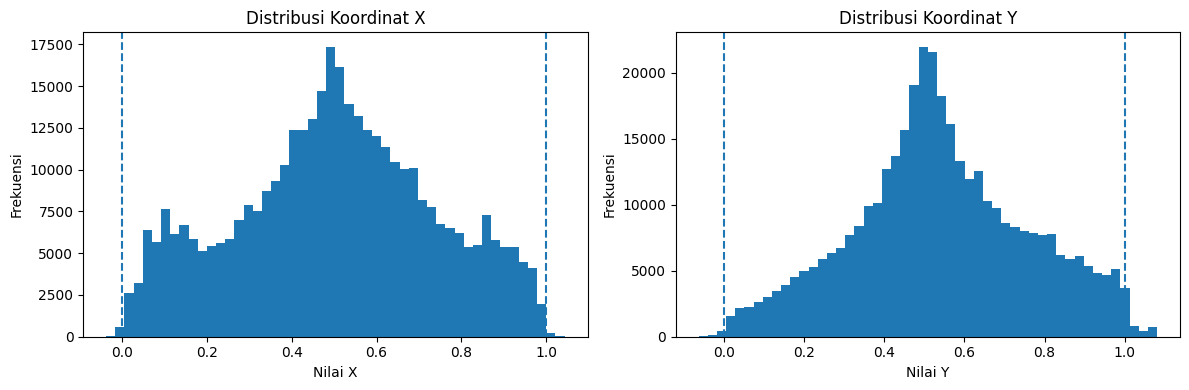

In [22]:

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Distribusi koordinat X
axes[0].hist(
    coordinate_samples["x"],
    bins=50
)
axes[0].axvline(0, linestyle="--")
axes[0].axvline(1, linestyle="--")
axes[0].set_title("Distribusi Koordinat X")
axes[0].set_xlabel("Nilai X")
axes[0].set_ylabel("Frekuensi")

# Distribusi koordinat Y
axes[1].hist(
    coordinate_samples["y"],
    bins=50
)
axes[1].axvline(0, linestyle="--")
axes[1].axvline(1, linestyle="--")
axes[1].set_title("Distribusi Koordinat Y")
axes[1].set_xlabel("Nilai Y")
axes[1].set_ylabel("Frekuensi")

plt.tight_layout()
plt.show()


In [23]:

speed_samples = coordinate_samples["speed"]

percentiles = [0, 25, 50, 75, 90, 95, 99, 100]

print("Statistik distribusi kecepatan:")

for p in percentiles:
    value = np.percentile(speed_samples, p)
    print(f"Persentil {p:>3}%: {value:.4f} m/s")


Statistik distribusi kecepatan:
Persentil   0%: 0.0012 m/s
Persentil  25%: 0.7749 m/s
Persentil  50%: 1.3352 m/s
Persentil  75%: 2.3113 m/s
Persentil  90%: 3.7138 m/s
Persentil  95%: 4.5393 m/s
Persentil  99%: 6.3795 m/s
Persentil 100%: 11.2938 m/s


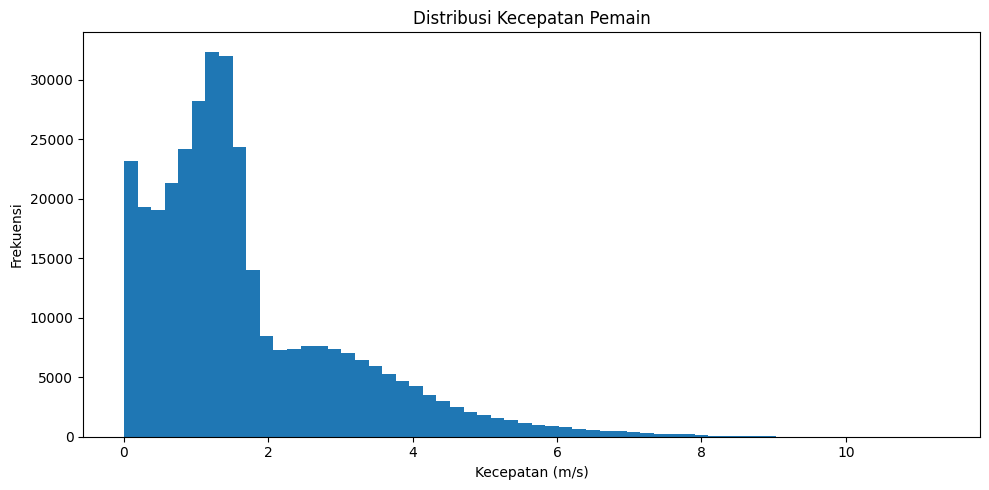

In [24]:

plt.figure(figsize=(10, 5))

plt.hist(
    speed_samples,
    bins=60
)

plt.title("Distribusi Kecepatan Pemain")
plt.xlabel("Kecepatan (m/s)")
plt.ylabel("Frekuensi")

plt.tight_layout()
plt.show()


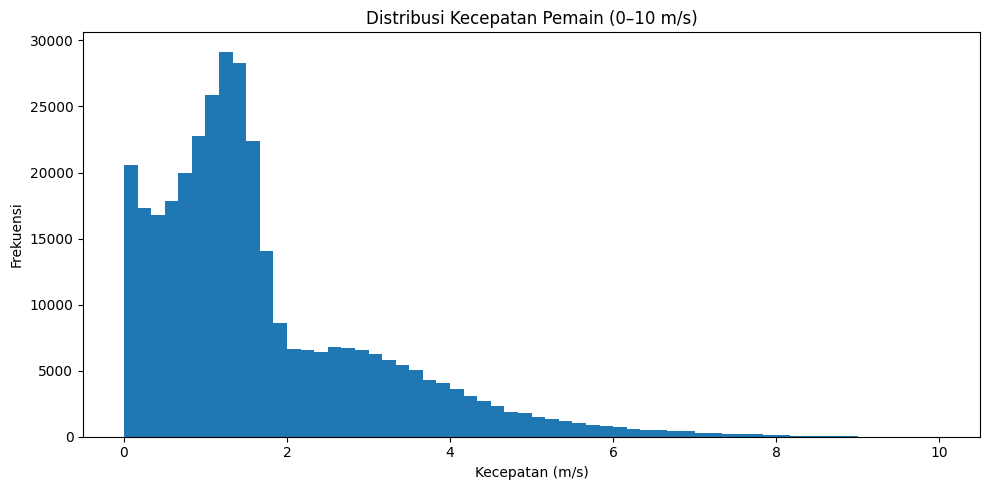

In [25]:

plt.figure(figsize=(10, 5))

plt.hist(
    speed_samples,
    bins=60,
    range=(0, 10)
)

plt.title("Distribusi Kecepatan Pemain (0–10 m/s)")
plt.xlabel("Kecepatan (m/s)")
plt.ylabel("Frekuensi")

plt.tight_layout()
plt.show()


In [26]:

from collections import defaultdict

# Menghitung hubungan ketersediaan bola dan pemain
stats = {
    "ball_detected": {
        "total_frames": 0,
        "total_players": 0
    },
    "ball_missing": {
        "total_frames": 0,
        "total_players": 0
    }
}

for record in iter_tracking(atd_path):

    if record["ball"] is not None:
        category = "ball_detected"
    else:
        category = "ball_missing"

    available = sum(
        player is not None
        for player in record["players"]
    )

    stats[category]["total_frames"] += 1
    stats[category]["total_players"] += available

for category, result in stats.items():

    total_frames = result["total_frames"]
    total_players = result["total_players"]

    average_players = total_players / total_frames

    print("\nKategori:", category)
    print("Jumlah frame:", total_frames)
    print("Total deteksi pemain:", total_players)
    print("Rata-rata pemain terdeteksi:", round(average_players, 2))



Kategori: ball_detected
Jumlah frame: 113488
Total deteksi pemain: 2268518
Rata-rata pemain terdeteksi: 19.99

Kategori: ball_missing
Jumlah frame: 85831
Total deteksi pemain: 1513903
Rata-rata pemain terdeteksi: 17.64
